In this model, there are 4 cells and 17 surfaces. It is relatively complicated. 

May not be to proportion (in the MCNP example, no measurements are provided). 

In [1]:
import openmc

# Surface definitions
s1 = openmc.ZPlane( z0 = 5)
s2 = openmc.ZPlane(z0 = -5)
s3 = openmc.YPlane( y0 = -5)
s4 = openmc.YPlane( y0 = 5)
s5 = openmc.XPlane(x0 = -5)
s6 = openmc.XPlane( x0= 5)
s7 = openmc.XPlane(x0=-1)
s8 = openmc.XPlane( x0=4)
s9 = openmc.YPlane(y0=-1)
s10 = openmc.YPlane(y0 = 0)
s11 = openmc.ZPlane( z0 = 3)
s12 = openmc.ZPlane(z0=-4)
s13 = openmc.YPlane( y0=-2)
s14 = openmc.XPlane( x0=2)
s15 = openmc.model.YConeOneSided(y0=0,r2=(3/5)**2, up=0)
s16 = openmc.model.YConeOneSided(y0=7,r2=(1)**2, up=0)
s17 = openmc.Sphere(r=20)


In [2]:
# Cell definitions
c2 = openmc.Cell(fill=None, region=(+s2 & -s12 & +s3 & - s13 & +s5 & -s6) | (+s11 & -s1 & +s9 & -s10 & +s7 & -s8))
c1 = openmc.Cell( fill=None, region=(+s3 & +s15 & +s2 & -s1 & -s4 & +s5 & -s6) & ~c2.region |  (+s4 & -s16))
c3 = openmc.Cell(fill=None,region=-s17 & (+s1 & -s2 & -s3 & -s15 & +s4 & +s16))
c4 = openmc.Cell(fill=None,region=+s17)

geometry=openmc.Geometry([c1, c2,c3,c4])
#print(geometry.get_all_surfaces())
geometry.export_to_xml()

In [3]:
material=openmc.Materials()
material.export_to_xml()

setting = openmc.Settings()
setting.export_to_xml()

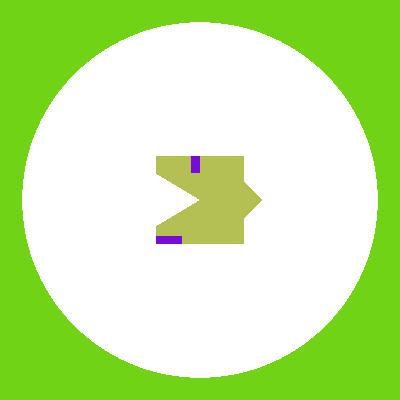

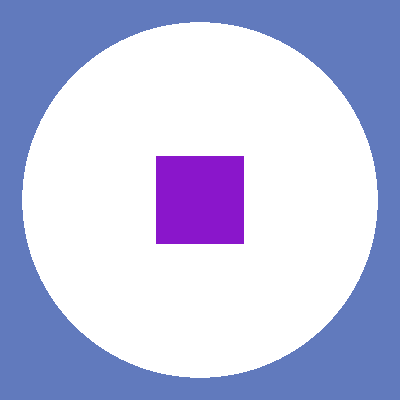

In [4]:
w = 45
plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots = openmc.Plots()
plots.append(plot)

plot=openmc.SlicePlot()
plot.basis= 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plots.append(plot)
openmc.plot_inline(plots)